In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
url = "https://raw.githubusercontent.com/Escavine/World-Happiness/main/World-happiness-report-2024.csv"
df = pd.read_csv(url)
print("Rows&Columns",df.shape)
display(df.head())

Rows&Columns (143, 12)


,Country name,Regional indicator,Ladder score,upperwhisker,lowerwhisker,Log GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Dystopia + residual
0,Finland,Western Europe,7.741,7.815,7.667,1.844,1.572,0.695,0.859,0.142,0.546,2.082
1,Denmark,Western Europe,7.583,7.665,7.500,1.908,1.520,0.699,0.823,0.204,0.548,1.881
2,Iceland,Western Europe,7.525,7.618,7.433,1.881,1.617,0.718,0.819,0.258,0.182,2.050
3,Sweden,Western Europe,7.344,7.422,7.267,1.878,1.501,0.724,0.838,0.221,0.524,1.658
4,Israel,Middle East and North Africa,7.341,7.405,7.277,1.803,1.513,0.740,0.641,0.153,0.193,2.298


In [3]:
print(df.columns.tolist())
df.info()
display(df.describe(include="all").T)

['Country name', 'Regional indicator', 'Ladder score', 'upperwhisker', 'lowerwhisker', 'Log GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption', 'Dystopia + residual']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143 entries, 0 to 142
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Country name                  143 non-null    object 
 1   Regional indicator            143 non-null    object 
 2   Ladder score                  143 non-null    float64
 3   upperwhisker                  143 non-null    float64
 4   lowerwhisker                  143 non-null    float64
 5   Log GDP per capita            140 non-null    float64
 6   Social support                140 non-null    float64
 7   Healthy life expectancy       140 non-null    float64
 8   Freedom to make life choices  140 non-null    fl

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Country name,143,143,Finland,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Regional indicator,143,10,Sub-Saharan Africa,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ladder score,143.0,NaN,NaN,NaN,5.52758,1.170717,1.721,4.726,5.785,6.416,7.741
upperwhisker,143.0,NaN,NaN,NaN,5.641175,1.155008,1.775,4.8455,5.895,6.5075,7.815
lowerwhisker,143.0,NaN,NaN,NaN,5.413972,1.187133,1.667,4.606,5.674,6.319,7.667
Log GDP per capita,140.0,NaN,NaN,NaN,1.378807,0.425098,0.0,1.07775,1.4315,1.7415,2.141
Social support,140.0,NaN,NaN,NaN,1.134329,0.333317,0.0,0.92175,1.2375,1.38325,1.617
Healthy life expectancy,140.0,NaN,NaN,NaN,0.520886,0.164923,0.0,0.398,0.5495,0.6485,0.857
Freedom to make life choices,140.0,NaN,NaN,NaN,0.620621,0.162492,0.0,0.5275,0.641,0.736,0.863
Generosity,140.0,NaN,NaN,NaN,0.146271,0.073441,0.0,0.091,0.1365,0.1925,0.401


In [4]:
missing_count = df.isna().sum()
missing_percent = (df.isna().mean()*100).round(2)
missing_report = pd.DataFrame({
    "missing_count":missing_count,
    "missing_percent": missing_percent
})
display(missing_report.sort_values("missing_percent",ascending=False))

,missing_count,missing_percent
Freedom to make life choices,3,2.1
Healthy life expectancy,3,2.1
Social support,3,2.1
Log GDP per capita,3,2.1
Perceptions of corruption,3,2.1
Generosity,3,2.1
Dystopia + residual,3,2.1
Country name,0,0.0
upperwhisker,0,0.0
Ladder score,0,0.0


In [5]:
print("ExactDuplicateRows",df.duplicated().sum())
print("RepeatedCountryNames",df["Country name"].duplicated().sum())
print("NumberOfCountries",df["Country name"].nunique())

ExactDuplicateRows 0
RepeatedCountryNames 0
NumberOfCountries 143


In [6]:
df.columns = df.columns.str.strip()
score_cols = [
    "Ladder score", "Log GDP per capita",
    "Social support", "Healthy life expectancy","Freedom to make life choices",
    "Generosity", "Perceptions of corruption"
]

for col in score_cols:
  if col in df.columns:
    df[col] = pd.to_numeric(df[col],errors="coerce")
print(df[score_cols].dtypes)

Ladder score                    float64
Log GDP per capita              float64
Social support                  float64
Healthy life expectancy         float64
Freedom to make life choices    float64
Generosity                      float64
Perceptions of corruption       float64
dtype: object


In [7]:
df["Happiness band"] = pd.cut(
    df["Ladder score"],
    bins = [0,4,5,6,7,10],
    labels = ["Very low","low","Middle","high","Very High"],
    include_lowest = True
)
df["GDP band"] = pd.qcut(
    df["Log GDP per capita"], q = 4,
    labels = ["Lowest quarter","Lower-middle","Upper-middle","Highest quarter"],
    duplicates="drop"


)

In [8]:
score = df["Ladder score"]
print(score.describe)
print("Mean",round(score.mean(),2))

<bound method NDFrame.describe of 0      7.741
1      7.583
2      7.525
3      7.344
4      7.341
       ...  
138    3.295
139    3.245
140    3.186
141    2.707
142    1.721
Name: Ladder score, Length: 143, dtype: float64>
Mean 5.53


In [10]:
ranked = df[["Country name","Regional indicator","Ladder score"]].dropna(subset=["Ladder score"]).copy()
ranked = ranked.sort_values("Ladder score",ascending=False)
ranked["Rank"] = range(1,len(ranked)+1)
display(ranked.head(10))

,Country name,Regional indicator,Ladder score,Rank
0,Finland,Western Europe,7.741,1
1,Denmark,Western Europe,7.583,2
2,Iceland,Western Europe,7.525,3
3,Sweden,Western Europe,7.344,4
4,Israel,Middle East and North Africa,7.341,5
5,Netherlands,Western Europe,7.319,6
6,Norway,Western Europe,7.302,7
7,Luxembourg,Western Europe,7.122,8
8,Switzerland,Western Europe,7.060,9
9,Australia,North America and ANZ,7.057,10


,count,mean,median,min,max
Regional indicator,,,,,
North America and ANZ,4,6.93,6.96,6.72,7.06
Western Europe,20,6.84,6.87,5.93,7.74
Central and Eastern Europe,17,6.17,6.26,5.30,6.82
Latin America and Caribbean,19,6.14,6.19,5.61,6.96
East Asia,6,5.93,6.02,5.32,6.50
Southeast Asia,9,5.55,5.98,4.34,6.52
Commonwealth of Independent States,10,5.54,5.58,4.87,6.20
Middle East and North Africa,17,5.20,4.97,2.71,7.34
Sub-Saharan Africa,35,4.33,4.38,3.19,5.82


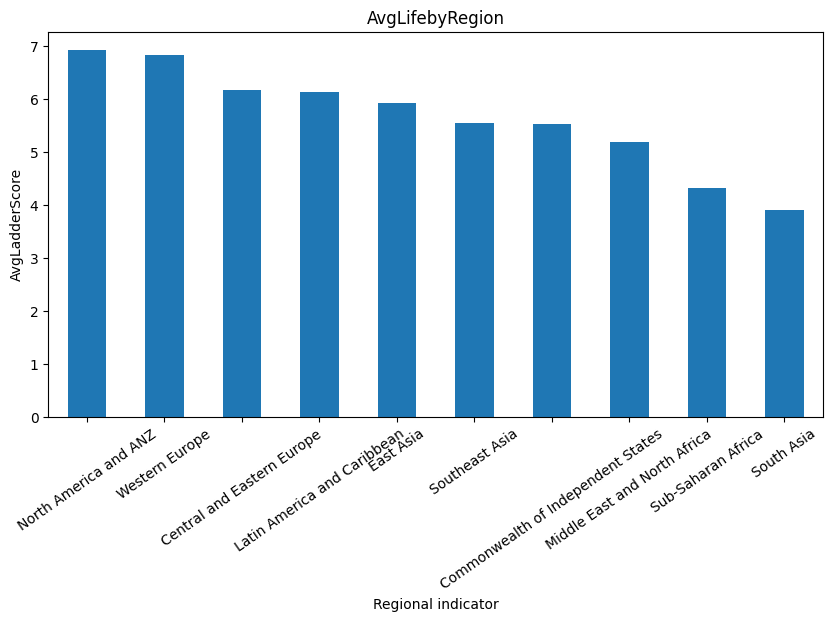

In [12]:
region_summary = (
    df.groupby("Regional indicator")["Ladder score"]
    .agg(["count","mean","median","min","max"])
    .round(2)
    .sort_values("mean",ascending=False)
)
display(region_summary)
region_summary["mean"].plot(kind="bar",figsize=(10,5))
plt.ylabel("AvgLadderScore")
plt.title("AvgLifebyRegion")
plt.xticks(rotation=35)
plt.show()

In [15]:
indicator_cols = [
    "Log GDP per capita","Social support","Healthy life expectancy","Freedom to make life choices","Generosity","Perceptions of corruption"
]
indicator_summary = df[indicator_cols].agg(["mean","median","min","max"]).T.round(3)
display(indicator_summary)

,mean,median,min,max
Log GDP per capita,1.379,1.432,0.0,2.141
Social support,1.134,1.238,0.0,1.617
Healthy life expectancy,0.521,0.550,0.0,0.857
Freedom to make life choices,0.621,0.641,0.0,0.863
Generosity,0.146,0.136,0.0,0.401
Perceptions of corruption,0.154,0.120,0.0,0.575


In [16]:
display(df.nlargest(10,"Social support")[
    ["Country name","Regional indicator","Social support","Ladder score"]
])

,Country name,Regional indicator,Social support,Ladder score
2,Iceland,Western Europe,1.617,7.525
0,Finland,Western Europe,1.572,7.741
44,Slovakia,Central and Eastern Europe,1.540,6.257
55,Hungary,Central and Eastern Europe,1.528,6.017
10,New Zealand,North America and ANZ,1.527,7.029
33,Estonia,Central and Eastern Europe,1.527,6.448
1,Denmark,Western Europe,1.520,7.583
6,Norway,Western Europe,1.517,7.302
4,Israel,Middle East and North Africa,1.513,7.341
17,Czechia,Central and Eastern Europe,1.511,6.822


In [17]:
display(df.nsmallest(10,"Freedom to make life choices")[
    ["Country name","Regional indicator","Freedom to make life choices","Ladder score"]
]
)

,Country name,Regional indicator,Freedom to make life choices,Ladder score
142,Afghanistan,South Asia,0.000,1.721
131,Comoros,Sub-Saharan Africa,0.172,3.566
141,Lebanon,Middle East and North Africa,0.173,2.707
97,Turkiye,Middle East and North Africa,0.202,4.975
84,Algeria,Middle East and North Africa,0.247,5.364
122,Madagascar,Sub-Saharan Africa,0.250,4.228
114,Tunisia,Middle East and North Africa,0.254,4.422
134,Eswatini,Sub-Saharan Africa,0.284,3.502
63,Greece,Western Europe,0.337,5.934
110,Mauritania,Sub-Saharan Africa,0.343,4.505


,Ladder score,Log GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
Ladder score,1.00,0.77,0.81,0.76,0.64,0.13,0.45
Log GDP per capita,0.77,1.00,0.73,0.83,0.41,-0.06,0.44
Social support,0.81,0.73,1.00,0.71,0.48,0.08,0.25
Healthy life expectancy,0.76,0.83,0.71,1.00,0.40,0.01,0.40
Freedom to make life choices,0.64,0.41,0.48,0.40,1.00,0.22,0.34
Generosity,0.13,-0.06,0.08,0.01,0.22,1.00,0.17
Perceptions of corruption,0.45,0.44,0.25,0.40,0.34,0.17,1.00


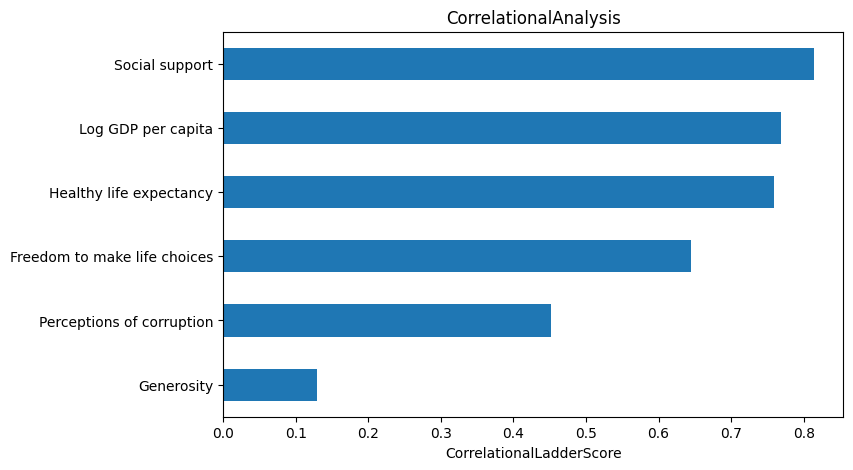

In [19]:
corr_col = ["Ladder score"] + indicator_cols
corr = df[corr_col].corr(numeric_only=True)
display(corr.round(2))


score_corr = corr["Ladder score"].drop("Ladder score").sort_values()
score_corr.plot(kind="barh",figsize=(8,5))
plt.xlabel("CorrelationalLadderScore")
plt.title("CorrelationalAnalysis")
plt.show()

Happiness band,Very low,low,Middle,high,Very High
Regional indicator,,,,,
Central and Eastern Europe,0.0,0.0,35.3,64.7,0.0
Commonwealth of Independent States,0.0,20.0,60.0,20.0,0.0
East Asia,0.0,0.0,50.0,50.0,0.0
Latin America and Caribbean,0.0,0.0,47.4,52.6,0.0
Middle East and North Africa,17.6,35.3,23.5,17.6,5.9
North America and ANZ,0.0,0.0,0.0,50.0,50.0
South Asia,50.0,33.3,16.7,0.0,0.0
Southeast Asia,0.0,22.2,44.4,33.3,0.0
Sub-Saharan Africa,31.4,48.6,20.0,0.0,0.0


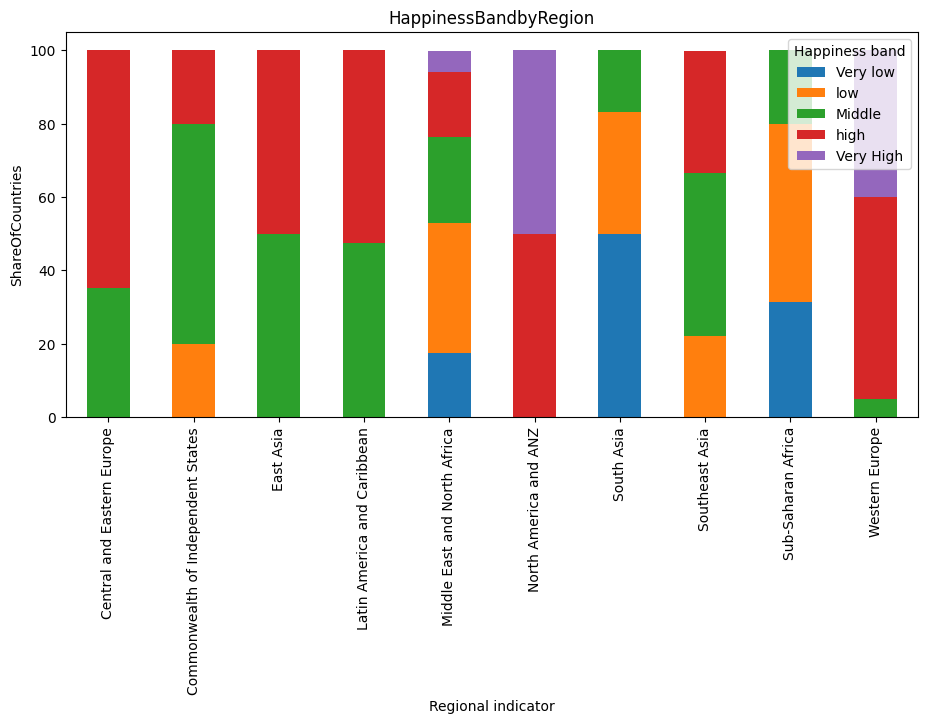

In [22]:
happiness_by_region = pd.crosstab(
    df["Regional indicator"],
    df["Happiness band"],
    normalize = "index"
).mul(100).round(1)
display(happiness_by_region)


happiness_by_region.plot(kind="bar",stacked=True,figsize=(11,5))
plt.ylabel("ShareOfCountries")
plt.title("HappinessBandbyRegion")
plt.show()

In [24]:
pivot = pd.pivot_table(
    df,
    index="Regional indicator",
    values = ["Ladder score","Log GDP per capita","Social support"],
    aggfunc={"Ladder score":"mean","Social support":"mean","Log GDP per capita":"mean"}

).round(2)
display(pivot.sort_values("Ladder score",ascending=False))

,Ladder score,Log GDP per capita,Social support
Regional indicator,,,
North America and ANZ,6.93,1.86,1.46
Western Europe,6.84,1.87,1.42
Central and Eastern Europe,6.17,1.64,1.39
Latin America and Caribbean,6.14,1.33,1.27
East Asia,5.93,1.70,1.30
Southeast Asia,5.55,1.37,1.14
Commonwealth of Independent States,5.54,1.40,1.25
Middle East and North Africa,5.20,1.46,1.08
Sub-Saharan Africa,4.33,0.90,0.79


In [28]:
kpis = {
    "Countries in file": df["Country name"].nunique(),
    "Regions represented": df["Regional indicator"].nunique(),
    "Average Ladder score": round(df["Ladder score"].mean(),2)

}
kpi_table = pd.DataFrame(list(kpis.items()),columns = ["KPI","Value"])
display(kpi_table)

,KPI,Value
0,Countries in file,143.00
1,Regions represented,10.00
2,Average Ladder score,5.53
